# Clase 13: estados, decisiones y espera

Estudiante · Universidad Austral · Cierre del curso

Un paso del régimen es un día. Observamos el régimen de hoy antes de reservar mañana. La ampliación de absorción usa meses; el simulador de colas usa horas y reporta espera en minutos. Los datos son sintéticos. Definimos todos los términos principales en diapositivas y apuntes.

**Andamiaje ejecutable:** quedan tres implementaciones pendientes, identificadas con mensajes. Los demás bloques son referencias para estudiar y contrastar, no prueba de trabajo propio completado. Antes de entregar, completar funciones y recomendación propia.

## Datos y funciones incluidos — versión autónoma

Este `.ipynb` puede copiarse solo a una carpeta vacía o subirse a Colab/Jupyter. **Ejecutar todas las celdas desde el principio**, con Python y `numpy`, `pandas`, `scipy`, `matplotlib` instalados. La primera celda contiene los archivos originales comprimidos, comprueba su integridad y los prepara en una carpeta temporal nueva. No descarga datos, no depende de rutas absolutas ni modifica archivos del usuario.

Se incluyen **1001 estados temporales (1000 transiciones)** en `historico_estados.csv`, las **200 demandas** de clase 12 en `historico_demanda_clase12.csv` y la tabla manual de cuatro clientes. Los dos históricos tienen propósitos distintos: uno calibra transiciones; el otro, la distribución de demanda por régimen. `estres.csv`, `colas.csv` y las réplicas son **resultados de referencia** del experimento documentado, no datos empresariales nuevos.

Todos los históricos son **sintéticos didácticos**. El inventario aparece al ejecutar la primera celda; sus bytes y los módulos de referencia también pueden consultarse en el ZIP. Los pendientes de implementación del estudiante se conservan como ejercicios; no son faltantes de datos.

Para acceder a un CSV completo después del inicio: `pd.read_csv(ROOT / "data" / "historico_estados.csv")`. La compresión permite incluir todos los registros sin pegar más de mil filas en el área de trabajo.

In [1]:
# INICIO RECURSOS AUTOCONTENIDOS IO 2026-10-26
from pathlib import Path
import base64, hashlib, io, zipfile, tempfile, sys, importlib, importlib.util
_IO_MANIFEST = {'scripts/modelo_base.py': '67470549ee32d5115a1acb74af13391aac79a727987ac67d64acd3bf7d8033a4', 'scripts/modelo_markov.py': '8430b3a1f1c8116bb7bfa134536794c0332645920bce57ccb81f375cdd85b21b', 'data/cola_manual.csv': 'a5c41aa845565d1e33fd5fa7c881c2c78c60d9b3505d2d7ef132f2663b8df27e', 'data/historico_demanda_clase12.csv': '100a89b0a8a6a74ad9b59927cc8c1d4e4be5eac2d4ce6b5ce5756371553731dd', 'data/historico_estados.csv': '624793ba03e386c992a2c4dbfeec2b61831aa26c6f05091a923a308e2b1337b5', 'results/P.csv': 'd277b26bdeb7df72238f1ec70c0dc4cd1e7f1bc145e29b7e8f61ce465b6b6f86', 'results/absorcion.csv': '5a015f8d3164bf47b882902b1bd254efef6849e07cf8d6027808f4c08a10bc82', 'results/bellman.csv': '6ee9b99e56b0d1ae9ff0939ab362ed56a56174ad5a343b58207d4f33cef6b1aa', 'results/cola_replicas_mu10.csv': '3d12365e10e5cc0b676b84360ae44fa225e72fa64455c9f92ccc9b4c32b620f2', 'results/cola_replicas_mu12.csv': '1be93ab09aefbe110f12d5b433ab2c1a1a3f5bebeac1fbcf6e04550256eb3f15', 'results/cola_replicas_mu16.csv': '61bae79336152f4e5199ebd3b009a45811278513eb876991b713f35b23628952', 'results/colas.csv': '83a5bb53f9715f6196212c47cf61808be4a107405a888ddf0a9ee3227a0692b2', 'results/estres.csv': 'b0a00cf23d53b6be037cc9e02f5ac0025afd5187b27f7e8d5f76d35ec5ec1a20', 'results/politicas_holdout.csv': '84a4d412afea53a90086e9a6a2478215aabd4fc303e0462cb664bac091355947', 'results/pronostico.csv': 'bcad90b1128272f8363c2c843cad32c16d3328c3af540ef881ade4fe70f6de1f', 'results/tabla_condicional.csv': '8371f55c253441b146566d690cd6e36758a7d0d5da3783bc1af6ddb836146bfb', 'results/configuracion.json': 'f9c5124bd30570b73681d426e6254fc8b0c2d56fa4d4e81e9559b3c163b6df41', 'results/politicas_congeladas.json': '8ed25dbab13adcb6b243486bf8eca5b3f4575172d1310953240d42ef50ffe484'}
_IO_ARCHIVO_B64 = '...'
_IO_ARCHIVO = base64.b64decode(_IO_ARCHIVO_B64)
if hashlib.sha256(_IO_ARCHIVO).hexdigest() != '6816c41473fdfab095f0b220964893a80198d5cfcf947cd7f81bb8e7b7ca39fe':
    raise ValueError('El bloque de recursos incluido está dañado; recuperar el notebook original.')
_IO_ROOT = Path(tempfile.mkdtemp(prefix='io_austral_clase13_'))
with zipfile.ZipFile(io.BytesIO(_IO_ARCHIVO)) as _z:
    if set(_z.namelist()) != set(_IO_MANIFEST):
        raise ValueError('El inventario de recursos no coincide.')
    for _nombre, _digest in _IO_MANIFEST.items():
        _ruta = Path(_nombre)
        if _ruta.is_absolute() or '..' in _ruta.parts:
            raise ValueError('Ruta de recurso inválida.')
        _contenido = _z.read(_nombre)
        if hashlib.sha256(_contenido).hexdigest() != _digest:
            raise ValueError('Recurso alterado: '+_nombre)
        _destino = _IO_ROOT/_ruta
        _destino.parent.mkdir(parents=True,exist_ok=True)
        _destino.write_bytes(_contenido)
_faltan = [p for p in ['numpy','pandas','scipy','matplotlib'] if importlib.util.find_spec(p) is None]
if _faltan:
    raise ModuleNotFoundError('Faltan dependencias: '+', '.join(_faltan)+'. Instalar numpy pandas scipy matplotlib con pip y reiniciar el kernel.')
# Evitar reutilizar un módulo del mismo nombre cargado por otra copia del taller.
for _modulo in ['modelo_base', 'modelo_markov']:
    sys.modules.pop(_modulo,None)
importlib.invalidate_caches()
print('Clase 13: recursos originales incluidos y verificados; no se necesitan carpetas externas.')
print('CSV disponibles:', ', '.join(k for k in _IO_MANIFEST if k.endswith('.csv')))
# FIN RECURSOS AUTOCONTENIDOS IO 2026-10-26

from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = _IO_ROOT
sys.path.insert(0,str(ROOT/'scripts'))
from modelo_markov import *
from modelo_base import calibrar
hist=pd.read_csv(ROOT/'data/historico_estados.csv')
m=calibrar(pd.read_csv(ROOT/'data/historico_demanda_clase12.csv'))
hist.head()

Clase 13: recursos originales incluidos y verificados; no se necesitan carpetas externas.
CSV disponibles: data/cola_manual.csv, data/historico_demanda_clase12.csv, data/historico_estados.csv, results/P.csv, results/absorcion.csv, results/bellman.csv, results/cola_replicas_mu10.csv, results/cola_replicas_mu12.csv, results/cola_replicas_mu16.csv, results/colas.csv, results/estres.csv, results/politicas_holdout.csv, results/pronostico.csv, results/tabla_condicional.csv
Out[1]: 
   t  regimen                         origen
0  0        0  sintetico_conteos_controlados
1  1        0  sintetico_conteos_controlados
2  2        0  sintetico_conteos_controlados
3  3        0  sintetico_conteos_controlados
4  4        0  sintetico_conteos_controlados


,t,regimen,origen
0,0,0,sintetico_conteos_controlados
1,1,0,sintetico_conteos_controlados
2,2,0,sintetico_conteos_controlados
3,3,0,sintetico_conteos_controlados
4,4,0,sintetico_conteos_controlados


## 1. Secuencia y estimación de transición

Cada fila se normaliza por su cantidad de orígenes. El histórico es sintético con conteos controlados.

In [2]:
def estimar_propio(z):
    # TODO: contar pares y normalizar por fila; informar filas sin datos.
    raise NotImplementedError('Completar estimación de la matriz')
try:
    count,P=estimar_propio(hist.regimen.to_numpy())
    np.testing.assert_array_equal(count,N_REF)
    np.testing.assert_allclose(P,P_REF)
    print('Prueba matriz propia aprobada')
except NotImplementedError as exc:
    print('IMPLEMENTACIÓN PENDIENTE:',exc)
# Referencia explícita para continuar el recorrido.
count,P=estimar_P(hist.regimen.to_numpy())
print('P DE REFERENCIA:',P)

IMPLEMENTACIÓN PENDIENTE: Completar estimación de la matriz
P DE REFERENCIA: [[0.94 0.06]
 [0.34 0.66]]


## 2. Un paso, varios pasos y distribución inicial

Notación: $Z_t$ es el estado; $\boldsymbol{p}_t$ el vector; $p_t(j)$ una componente marginal; $p_{ij}^{(k)}$ la probabilidad condicional desde $i$. `p_t` en el código representa el vector fila; `P_k[i,j]` representa el escalar $p_{ij}^{(k)}$. Conservar los ceros y comparar producto matricial con potencia por elementos.

**Referencia ejecutable:** explicar las decisiones y contrastar con tus cálculos.

Vector futuro desde mezcla: [0.82 0.18] Probabilidad marginal alta: 0.18000000000000002
Vector inicial: [1. 0.] Términos por origen (incluyen ceros): [[0.94 0.06]
 [0.   0.  ]] Suma por destino: [0.94 0.06]
Vector inicial: [0. 1.] Términos por origen (incluyen ceros): [[0.   0.  ]
 [0.34 0.66]] Suma por destino: [0.34 0.66]
Identidad (cero pasos): [[1. 0.]
 [0. 1.]] P al cuadrado: [[0.904 0.096]
 [0.544 0.456]]
k= 0 p_01^(k)= 0.0 p_11^(k)= 1.0
k= 1 p_01^(k)= 0.06 p_11^(k)= 0.66
k= 2 p_01^(k)= 0.09599999999999999 p_11^(k)= 0.456
k= 3 p_01^(k)= 0.11759999999999998 p_11^(k)= 0.3336


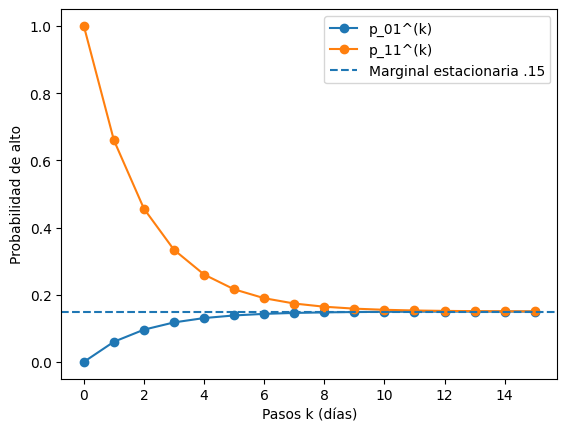

In [3]:
p_t=np.array([.8,.2])
p_futuro=p_t@P
np.testing.assert_allclose(p_futuro,[.82,.18])
print('Vector futuro desde mezcla:',p_futuro,'Probabilidad marginal alta:',p_futuro[1])
for inicial in [np.array([1.,0.]),np.array([0.,1.])]:
    terminos=inicial[:,None]*P
    print('Vector inicial:',inicial,'Términos por origen (incluyen ceros):',terminos,'Suma por destino:',terminos.sum(axis=0))
    np.testing.assert_allclose(terminos.sum(axis=0),inicial@P)
I=np.eye(2)
P2_manual=np.array([[.94*.94+.06*.34,.94*.06+.06*.66],[.34*.94+.66*.34,.34*.06+.66*.66]])
np.testing.assert_allclose(P@P,P2_manual)
np.testing.assert_allclose(P2_manual@P,[[.8824,.1176],[.6664,.3336]])
np.testing.assert_allclose(np.linalg.matrix_power(P,0),I)
assert not np.allclose(P**2,P@P)
print('Identidad (cero pasos):',I,'P al cuadrado:',P2_manual)
for k in [0,1,2,3]:
    P_k=np.linalg.matrix_power(P,k)
    print('k=',k,'p_01^(k)=',P_k[0,1],'p_11^(k)=',P_k[1,1])
for origen in [0,1]:
    prob=np.array([np.linalg.matrix_power(P,k)[origen,1] for k in range(16)])
    plt.plot(range(16),prob,'o-',label=f'p_{origen}1^(k)')
plt.axhline(.15,linestyle='--',label='Marginal estacionaria .15');plt.xlabel('Pasos k (días)');plt.ylabel('Probabilidad de alto');plt.legend();plt.show()

## 3. Estacionariedad, rachas y suma de costos

La igualdad $\boldsymbol{\pi}P=\boldsymbol{\pi}$ se verifica sumando entradas y salidas. $I$ conserva cualquier distribución; $P$ conserva la estacionaria del caso. La fila alta determina continuar o salir. Un costo aditivo suma costos diarios y una reserva fija mantiene el mismo $q$.

**Referencia ejecutable:** explicar las decisiones y contrastar con tus cálculos.

In [4]:
pi=estacionaria(P)
terminos_pi=pi[:,None]*P
np.testing.assert_allclose(pi,[.85,.15]);np.testing.assert_allclose(terminos_pi.sum(axis=0),pi)
print('Términos de pi por P:',terminos_pi,'Suma por destino:',pi@P)
np.testing.assert_allclose([pi[0]*P[0,1],pi[1]*P[1,0]],[.051,.051])
alt=np.array([[0.,1.],[1.,0.]])
print('Alternancia:',[np.array([1.,0.])@np.linalg.matrix_power(alt,k) for k in range(5)])
for vector in [np.array([1.,0.]),np.array([0.,1.]),np.array([.85,.15])]:
    np.testing.assert_allclose(vector@I,vector)
try:estacionaria(I)
except ValueError as e:print('Unicidad rechazada correctamente:',e)
continuar=P[1,1];salir=P[1,0];m_racha=1/salir
np.testing.assert_allclose(m_racha,1+continuar*m_racha+salir*0)
P_ind=np.array([[.85,.15],[.85,.15]])
np.testing.assert_allclose(pi@P_ind,pi)
print('Desde alto: continuar=',continuar,'salir=',salir,'Racha media=',m_racha)
print('En independencia: continuar=',P_ind[1,1],'salir=',P_ind[1,0],'Racha media=',1/P_ind[1,0])
g_persistente,_=tabla_costos(P,m);g_independiente,_=tabla_costos(P_ind,m)
media_fija=pi@g_persistente
np.testing.assert_allclose(media_fija,pi@g_independiente)
print('Medias exactas para el mismo q fijo:',pd.DataFrame({'q':Q,'media_diaria':media_fija,'media_total_30':30*media_fija}).to_string(index=False))
print('El resultado compara reserva fija, costo diario aditivo e inicio estacionario; no una reserva adaptativa.')

Términos de pi por P: [[0.799 0.051]
 [0.051 0.099]] Suma por destino: [0.85 0.15]
Alternancia: [array([1., 0.]), array([0., 1.]), array([1., 0.]), array([0., 1.]), array([1., 0.])]
Unicidad rechazada correctamente: Distribución estacionaria no única
Desde alto: continuar= 0.66 salir= 0.34 Racha media= 2.941176470588235
En independencia: continuar= 0.15 salir= 0.85 Racha media= 1.1764705882352942
Medias exactas para el mismo q fijo:   q  media_diaria  media_total_30
100   2644.497805    79334.934151
105   2551.677297    76550.318915
110   2490.317374    74709.521212
115   2454.676484    73640.294521
120   2441.971153    73259.134595
125   2450.391375    73511.741243
130   2477.759059    74332.771784
135   2521.312900    75639.387012
140   2578.068032    77342.040952
145   2645.187016    79355.610493
150   2720.157468    81604.724027
El resultado compara reserva fija, costo diario aditivo e inicio estacionario; no una reserva adaptativa.


## 4. Transición simulada

Declarar la convención: seleccionar alto si U es menor que la probabilidad de alto de la fila.

In [5]:
def transicion_propia(estado,u,P):
    # TODO: devolver estado 0 o 1 usando solo origen, uniforme y matriz.
    raise NotImplementedError('Completar transición de un paso')
try:
    assert transicion_propia(0,.20,P)==0
    assert transicion_propia(1,.20,P)==1
    print('Pruebas de transición aprobadas')
except NotImplementedError as exc:print('IMPLEMENTACIÓN PENDIENTE:',exc)

IMPLEMENTACIÓN PENDIENTE: Completar transición de un paso


## 5. Mezclas predictivas y servicio

q de mañana usa el régimen de hoy. Separar criterio marginal y condicional.

**Referencia ejecutable:** explicar las decisiones y contrastar con tus cálculos.

In [6]:
acts,g,r,f=seleccionar_condicional(P,m)
print('Reservas por estado:',Q[acts])
np.testing.assert_array_equal(Q[acts],[105,145])
assert r[1,5]>.05 and pi@r[:,5]<.05
assert np.all(r[:,8]<.05)
print(pd.DataFrame({'q':Q,'costo_O':g[0],'costo_A':g[1],'p_inc_O':r[0],'p_inc_A':r[1]}))
frozen={'P':P.tolist(),'regla_sin_ajuste':Q[acts].tolist(),'requisito':'5% condicional en cada origen'}
print('REGLA CONGELADA:',frozen)

Reservas por estado: [105 145]
      q      costo_O      costo_A   p_inc_O   p_inc_A
0   100  2165.361650  5359.602684  0.050699  0.555367
1   105  2164.350521  4746.529030  0.044880  0.493366
2   110  2186.929694  4209.514228  0.037837  0.416170
3   115  2224.532021  3758.828439  0.030000  0.330000
4   120  2272.914576  3399.958424  0.022166  0.243831
5   125  2330.175849  3131.612689  0.015150  0.166645
6   130  2395.105982  2946.126500  0.009519  0.104712
7   135  2466.525389  2831.775464  0.005473  0.060199
8   140  2543.227230  2775.499240  0.002867  0.031542
9   145  2624.074808  2764.822866  0.001365  0.015015
10  150  2708.062987  2788.692857  0.000589  0.006478
REGLA CONGELADA: {'P': [[0.94, 0.06], [0.34, 0.66]], 'regla_sin_ajuste': [105, 145], 'requisito': '5% condicional en cada origen'}


## 6. Holdout de trayectorias y comparación pareada

La réplica es la trayectoria completa. El holdout es simulado y no valida mediciones empresariales.

**Referencia ejecutable:** explicar las decisiones y contrastar con tus cálculos.

In [7]:
out,z,d=evaluar_politicas(P,m,n=10000,T=30,kappa=0.)
rows=[]
for nombre,item in out.items():
    total=item['total']
    rows.append({'politica':nombre,'media_dia':total.mean()/30,'se_dia':total.std(ddof=1)/np.sqrt(len(total))/30,'CVaR95_total':cola(total)[1],'inc':item['inc'].mean()})
tabla_hold=pd.DataFrame(rows);print(tabla_hold.to_string(index=False))
delta=(out['adaptativa']['total']-out['fija140']['total'])/30
se=delta.std(ddof=1)/np.sqrt(len(delta))
print('Adaptativa menos fija140:',delta.mean(),'IC95:',(delta.mean()-1.96*se,delta.mean()+1.96*se))
assert np.array_equal(out['adaptativa']['total'],out['bellman']['total'])

  politica   media_dia   se_dia  CVaR95_total      inc
   fija125 2449.767132 2.069717  91007.562239 0.037643
   fija140 2577.797143 0.719003  83949.323475 0.007153
adaptativa 2253.956621 2.707560  87437.638721 0.040487
   bellman 2253.956621 2.707560  87437.638721 0.040487
Adaptativa menos fija140: -323.8405218900598 IC95: (np.float64(-328.158297376951), np.float64(-319.5227464031686))


## 7. Estrés de políticas congeladas

Leer la evaluación bajo supuestos alternativos. La tabla no reselecciona para cada caso.

**Referencia ejecutable:** explicar las decisiones y contrastar con tus cálculos.

In [8]:
stress=pd.read_csv(ROOT/'results/estres.csv');stress=stress[stress.kappa==0]
print(stress.to_string(index=False))
print('El estrés de este bloque usa costo de ajuste cero; el CSV incluye también la ampliación con kappa20.')
print('Las reglas se fijaron con el modelo base; adoptar una regla nueva requiere otra evaluación.')

 kappa         caso   politica   media_dia  CVaR95_total  incumplimiento  racha
   0.0         base    fija125 2450.704792  90714.445689        0.037953 0.0280
   0.0         base    fija140 2578.333220  83881.135860        0.007447 0.0002
   0.0         base adaptativa 2255.901561  87005.150431        0.041120 0.0000
   0.0         base    bellman 2255.901561  87005.150431        0.041120 0.0000
   0.0 persistencia    fija125 2451.097613  96742.298381        0.037993 0.0384
   0.0 persistencia    fija140 2578.430135  85400.157486        0.007420 0.0002
   0.0 persistencia adaptativa 2152.315600  84483.264714        0.022160 0.0000
   0.0 persistencia    bellman 2152.315600  84483.264714        0.022160 0.0000
   0.0 frecuencia25    fija125 2589.752256  97780.810908        0.064713 0.0522
   0.0 frecuencia25    fija140 2618.987596  86345.459818        0.012433 0.0004
   0.0 frecuencia25 adaptativa 2452.690865  94765.642976        0.061007 0.0000
   0.0 frecuencia25    bellman 2452.6908

## 8. Ampliación: Bellman y costo de ajustar

Estado=(régimen actual,reserva previa); horizonte 30. Costo de ajuste 20 UM por unidad cambiada.

**Referencia ejecutable:** explicar las decisiones y contrastar con tus cálculos.

In [9]:
V,pol=bellman(P,T=30,kappa=20.,m=m)
assert Q[pol[1,0,5]]==125 and Q[pol[30,0,5]]==105
myopic=lambda h,z,a:int(acts[z])
V_myopic=valor_politica(P,30,20.,myopic,m)
assert np.all(V[30]<=V_myopic+1e-8)
print('Valor esperado diario Bellman:',pi@V[30,:,5]/30)
print('Valor esperado diario adaptativa:',pi@V_myopic[:,5]/30)
print('Acciones con previo125:',{h:Q[pol[h,:,5]].tolist() for h in [1,7,30]})

Valor esperado diario Bellman: 2336.9445904831537
Valor esperado diario adaptativa: 2346.634705919414
Acciones con previo125: {1: [125, 140], 7: [105, 140], 30: [105, 140]}


## 9. Ampliación: absorción

Cada paso del ejemplo de clientes es un mes.

**Referencia ejecutable:** explicar las decisiones y contrastar con tus cálculos.

In [10]:
PA=np.array([[.8,.15,.05],[.25,.6,.15],[0.,0.,1.]])
h=absorcion(PA)
np.testing.assert_allclose((np.eye(2)-PA[:2,:2])@h,[1,1])
print('Meses hasta baja:',h)

Meses hasta baja: [12.94117647 10.58823529]


## 10. FIFO con prueba manual

La tabla usa minutos. Implementar inicios, salidas y esperas antes de simular arribos.

In [11]:
def fifo_propio(a,s):
    # TODO: retornar inicios, salidas y esperas en las mismas unidades.
    raise NotImplementedError('Completar motor FIFO')
try:
    starts,fin,wait=fifo_propio(np.array([0.,1.,1.5,4.]),np.array([2.,2.,1.,1.5]))
    np.testing.assert_allclose(starts,[0,2,4,5]);np.testing.assert_allclose(fin,[2,4,5,6.5]);np.testing.assert_allclose(wait,[0,1,2.5,1])
    print('Pruebas FIFO aprobadas')
except NotImplementedError as exc:print('IMPLEMENTACIÓN PENDIENTE:',exc)

IMPLEMENTACIÓN PENDIENTE: Completar motor FIFO


## 11. M/M/1 y verificación de una réplica

Tiempo en horas y esperas mostradas en minutos. Calentamiento para largo plazo; cohorte de arribo sin censura.

**Referencia ejecutable:** explicar las decisiones y contrastar con tus cálculos.

In [12]:
for mu in [10.,12.,16.]:
    th=teoria_mm1(8,mu);sim=simular_cola(20261105,mu=mu)
    assert abs(sim['identidad_area'])<1e-8
    print('mu=',mu,'Wq teoría (min)=',60*th['Wq'],'una réplica=',60*sim['Wq'])
comparison=pd.read_csv(ROOT/'results/colas.csv');print(comparison.to_string(index=False))
assert np.all(abs(comparison.Wq_sim_min-comparison.Wq_teor_min)<5*comparison.se_Wq_min)
print('Referencias dentro de tolerancia estadística entre réplicas')

mu= 10.0 Wq teoría (min)= 24.0 una réplica= 21.003150171163604
mu= 12.0 Wq teoría (min)= 10.0 una réplica= 9.322903935138761
mu= 16.0 Wq teoría (min)= 3.75 una réplica= 3.4673680483655995
  mu  Wq_teor_min  Wq_sim_min  se_Wq_min  Lq_teor   Lq_sim  rho_teor  rho_sim  max_error_area
10.0        24.00   24.044328   0.250565 3.200000 3.209665  0.800000 0.799688    1.818989e-12
12.0        10.00    9.942692   0.059238 1.333333 1.327006  0.666667 0.666394    6.821210e-13
16.0         3.75    3.726209   0.016451 0.500000 0.497281  0.500000 0.499789    3.410605e-13
Referencias dentro de tolerancia estadística entre réplicas


## 12. Recomendación

Entregar 250–350 palabras con criterio, información, unidades, holdout, estrés y lo que falta observar en operación real.

**Referencia ejecutable:** explicar las decisiones y contrastar con tus cálculos.

In [13]:
print('La regla 105/145 minimiza media con servicio condicional bajo el modelo sin ajuste. Fija140 tiene menor cola acumulada. Con ajuste se requiere reserva previa y Bellman. En la cola, aumentar mu reduce demora nominal pero falta fijar costo y objetivo empresarial. Los históricos son sintéticos y la aplicación exige datos temporales reales reservados.')

La regla 105/145 minimiza media con servicio condicional bajo el modelo sin ajuste. Fija140 tiene menor cola acumulada. Con ajuste se requiere reserva previa y Bellman. En la cola, aumentar mu reduce demora nominal pero falta fijar costo y objetivo empresarial. Los históricos son sintéticos y la aplicación exige datos temporales reales reservados.


## Recomendación propia

Pendiente: escribir aquí 250–350 palabras, usando las preguntas y condiciones del ejercicio 28.